# Clustering with Outlier Removal Implementation

In [1]:

import pandas as pd
import numpy as np

from utils.data_utils import *
from utils.cor_utils import *
from utils.evaluation import *
%load_ext autoreload
%autoreload 2


COR Algorithm

In [2]:
def COR(X: pd.DataFrame, K: int, o:int, r:int, n_init: int = 1, k_max: int = None, additional_bp: list = None, verbose: bool = False, seed: int = None)-> tuple[np.ndarray, float, dict]:
    """
    Main function; runs the COR algorithm as presented in the paper. In this version, if the dataset contains categorical columns,
    it is left possible to use them as additional basic partitions. 
    
    Inputs:
    -   X: the data matrix
    -   K: the number of clusters
    -   o: the number of outliers
    -   r: the number of basic partitions generated by K-means
    -   n_init: the number of times we run K-means--
    -   k_max: the maximum number cluster each basic partition can contain; if not provided, it is set to 2*K
    -   additional_bp: the list of extra basic partitions 
    -   verbose: a boolean that, if set to True, enables a log of every iteration; False by default
    -   seed: an integer value for reproducibility; not set by default
    
    Outputs:
    -   The final partition in the form of a vector of labels
    -   The minimum objective value obtained
    -   Some run statistics
    """
    #setup
    if k_max is None:
        k_max = 2*K
    basic_partitions_labels = generate_basic_partitions(X, r, k_max=k_max, seed = seed)
    if additional_bp:
        basic_partitions_labels += additional_bp #categorical columns are turned into basic partitions

    B, tilde_B = build_binary_matrices(basic_partitions_labels)
    BB = np.hstack([B,tilde_B])
    best_obj_value = np.inf
    best_labels = None
    run_statistics = { "obj_values": [], "labels" : [],"iterations" : []}


    for i in range(n_init): #we run K-means-- n_init times#
        centroids = generate_centroids(BB, K)
        iter = 0  
        prev_obj_value = np.inf  


        while (iter<1000):
            iter+= 1 
            c_labels, min_distances= compute_kl_distances(BB, centroids= centroids)
            outlier_candidates = extract_outliers(min_distances, o) 
            c_labels[outlier_candidates] = -1
            centroids = update_centroids(BB, c_labels,centroids)
            obj_value = compute_holoentropy(BB, c_labels, centroids)

            if(prev_obj_value < obj_value):
                print("Objective value increased: force-quitted.")

                break
            elif (prev_obj_value-obj_value<= 1e-10): #the while cycle terminates once the marginal difference gets too small
                break

            if verbose:
                print(f"Run: {i}. Iteration: {iter}; objective value: {obj_value}\n")
            prev_obj_value = obj_value


        if obj_value < best_obj_value:
            best_obj_value = obj_value
            best_labels = c_labels

        run_statistics["iterations"].append(iter)
        run_statistics["labels"].append(c_labels)
        run_statistics["obj_values"].append(obj_value)

    return best_labels, best_obj_value, run_statistics

## Datasets and tests

In [3]:
n_init = 10 #number of tests per dataset
r = 50
seed = 42

### Statlog Shuttle

In [14]:
header = ["A1", "A2", "A3", "A4", "A5", "A6", "A7", "A8", "A9", "Class"]
shuttle_train = pd.read_csv("datasets/statlog+shuttle/train_shuttle.csv", sep = ",",header=None, names=header)
shuttle_test  = pd.read_csv("datasets/statlog+shuttle/test_shuttle.csv", sep = ",",header=None, names = header)
shuttle = pd.concat([shuttle_train,shuttle_test], ignore_index=True)
# shuttle.info()
# shuttle.describe()
shuttle_target  = shuttle.Class
shuttle.drop("Class",axis = 1, inplace = True)
# plot_correlation(shuttle)

r_cols = find_most_redundant_columns(shuttle,3)
shuttle = shuttle.drop(columns=r_cols)

# -------------------------------------------------

# shuttle_target.value_counts()
shuttle = standardise(shuttle)
outlier_indexes = shuttle[shuttle_target.isin([2, 3, 6, 7])].index   # 2,3,6,7 are the classes considered outlier set by the paper; found with value_counts()
true_outliers_shuttle = np.zeros(len(shuttle), dtype=bool)
true_outliers_shuttle[outlier_indexes] = True


cor_labels_shuttle,shuttle_obj, shuttle_stats = COR(shuttle, K = 3, o=len(true_outliers_shuttle[true_outliers_shuttle==True]),r = r,n_init= n_init, seed = seed)
# PCA_scatter_plot(shuttle,cor_labels_shuttle,true_outliers_shuttle)
r_cols

['A9', 'A7', 'A8']

### Wine

In [ ]:
red_wine_quality = pd.read_csv("datasets/wine+quality/winequality-red.csv",delimiter=";")
# red_wine_quality.info()
# red_wine_quality.describe()
red_target = red_wine_quality["quality"].to_numpy()
red_wine_quality.drop("quality",axis=1, inplace=True)
# plot_correlation(red_wine_quality)

# -----------------------------------------------------

red_wine_quality = standardise(red_wine_quality)
cor_labels_red_wine, red_wine_obj, red_wine_stats = COR(red_wine_quality,len(np.unique(red_target)),int(len(red_wine_quality)*0.1), r= r, n_init=n_init, seed = seed)
# PCA_scatter_plot(red_wine_quality, cor_labels_red_wine)


In [ ]:
white_wine_quality = pd.read_csv("datasets/wine+quality/winequality-white.csv",delimiter=";")
# white_wine_quality.info()
# white_wine_quality.describe()
white_target = white_wine_quality["quality"].to_numpy()
white_wine_quality.drop("quality",axis = 1, inplace = True)
# plot_correlation(white_wine_quality)

# --------------------------------------------------------

white_wine_quality = standardise(white_wine_quality)
cor_labels_white_wine, white_wine_obj, white_wine_stats = COR(white_wine_quality,len(np.unique(white_target)), int(len(white_wine_quality)*0.00), r = r, n_init = n_init, seed = seed)
# PCA_scatter_plot(white_wine_quality,labels=cor_labels_white_wine)

### Credit Card Fraud 


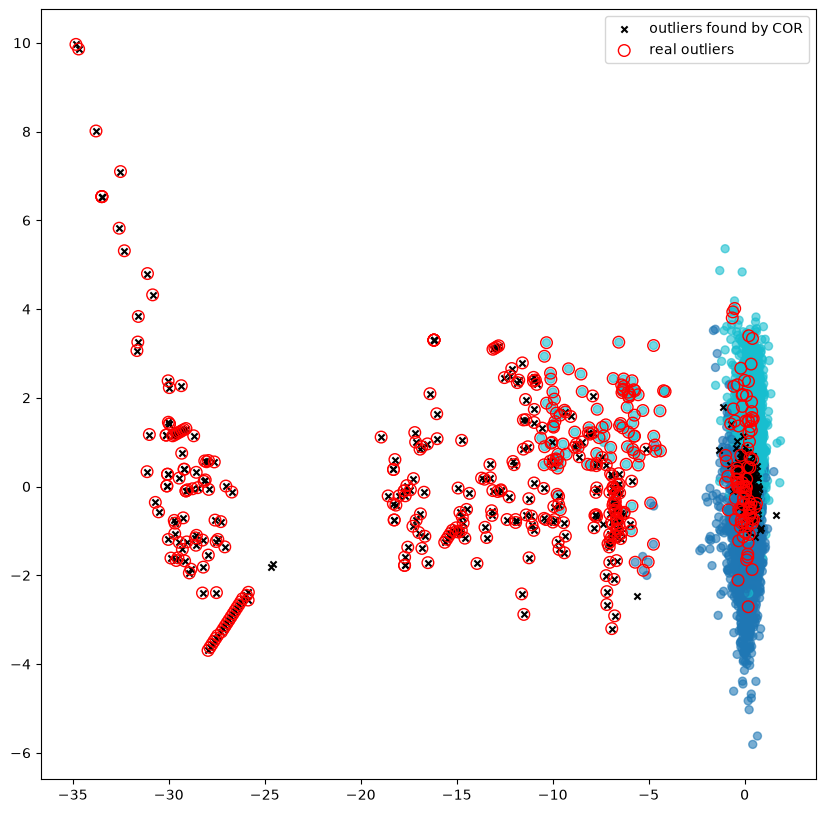

In [11]:
ccf = pd.read_csv("datasets/creditcard.csv", sep=",")
# ccf.info()
# ccf.describe()
# plot_correlation(ccf.drop("Class", axis = 1), show_values=False)

# -------------------------------------------------

frauds = ccf[ccf["Class"] == 1].sample(frac = 1, random_state=seed) #change the frac input to consider less outliers
no_frauds = ccf[ccf["Class"] == 0].sample(25000, random_state=seed)
ccf = pd.concat([no_frauds, frauds]).sample(frac=1, random_state=seed).reset_index(drop=True)

ccf_target = ccf["Class"]
true_outliers_ccf = (ccf_target == 1)
ccf = ccf.drop(columns="Class")

ccf["Amount"] = np.log(1+ccf["Amount"]) #there is too much variability; it's to avoid false outliers

# -------------------------------------------------

ccf = standardise(ccf)            
cor_labels_ccf, ccf_obj, ccf_stats = COR(ccf, 2, o=len(frauds), r=r, n_init=n_init, seed=seed)

PCA_scatter_plot(ccf, cor_labels_ccf, true_outliers_ccf)               

### Forestfires


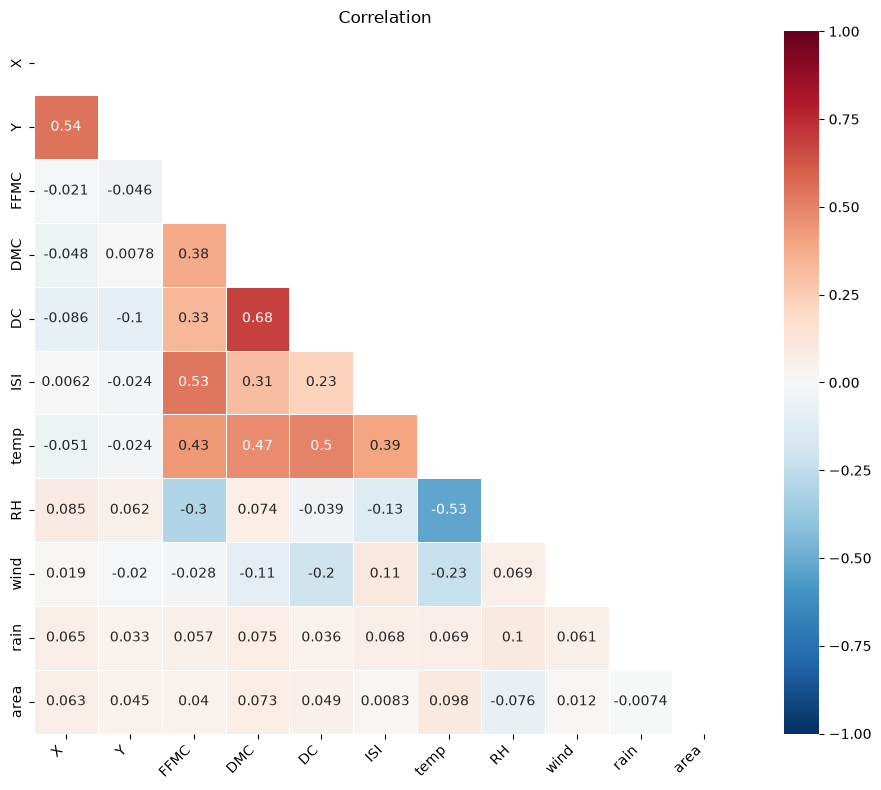

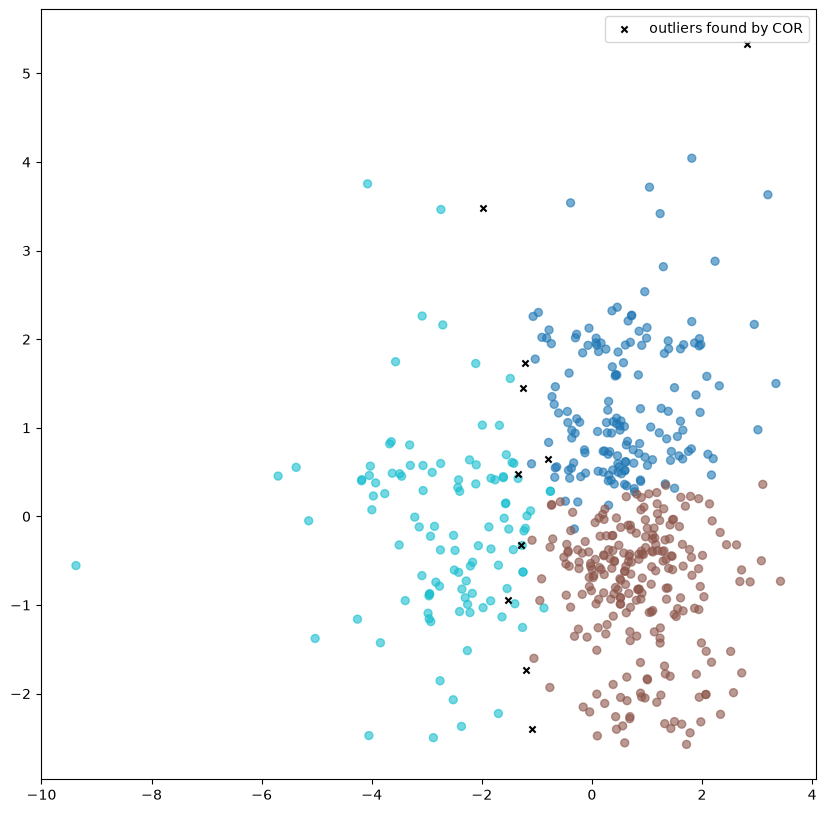

In [55]:
fires = pd.read_csv("datasets/forestfires.csv")
# fires.info()
# fires.describe()
plot_correlation(fires)

#---------------------------------------------------

fires, add_parts_fires = make_categoric_partitions(fires)
fires = standardise(fires)
cor_labels_fires,fires_obj, fires_stats = COR(fires, 3, int(len(fires)*0.02), r = r,n_init=n_init, additional_bp=add_parts_fires, seed = seed)

PCA_scatter_plot(fires, cor_labels_fires)


## Performances Evaluation

In [12]:
#stats_shuttle = runs_statistics(shuttle_stats,shuttle_target,true_outliers_shuttle)
#stats_red = runs_statistics(red_wine_stats, red_target)
#stats_white = runs_statistics(white_wine_stats,white_target)
stats_ccf = runs_statistics(ccf_stats, true_outliers=true_outliers_ccf)
#stats_fire = runs_statistics(fires_stats)

stats_ccf

,objective value,iterations,NMI,R_n,Jaccard,F-measure
mean,313204.601691,4.900000,NaN,NaN,0.431217,0.596748
std,55685.844409,0.737865,NaN,NaN,0.097816,0.095421


In [ ]:
evaluate_COR(cor_labels_shuttle,shuttle_target.to_numpy(), true_outliers_shuttle)

{'NMI': 0.32652662906563756,
 'R_n': 0.458674828718768,
 'Jaccard': 0.023060796645702306,
 'F-measure': 0.045081967213114756}

### Sensitivity to K and o: Test on Forest Fires

In [ ]:
fires = pd.read_csv("datasets/forestfires.csv")
fires, add_parts_fires = make_categoric_partitions(fires)
fires = standardise(fires)

dots = 15
K_values = np.arange(2,dots + 2)
o_percentages = np.arange(0,0.01*dots,0.01)      

performance = np.zeros(shape = (dots,dots))
for k_index, K, in enumerate(K_values):
    for o_index, o in enumerate(o_percentages):
        performance[k_index][o_index] = COR(X = fires, K = K, o = int(len(fires)*o),r = 50, n_init = 10, 
                                            k_max=max(K_values)*2, additional_bp=add_parts_fires, seed = 42)[1]


In [ ]:
obj_min = performance.min()
rows, cols = np.where(performance == obj_min)
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")

o_grid, K_grid = np.meshgrid([100 * p for p in o_percentages], K_values)
ax.plot_surface(o_grid, K_grid, performance, cmap="viridis", edgecolor="k", linewidth=0.3, alpha=0.85)


for k in range(len(rows)):
    K_min = K_values[rows[k]]
    o_min = int(o_percentages[cols[k]] * 100)
    ax.scatter(o_min, K_min, obj_min, color="red", s=60, depthshade=False)
    print(f"Minimum: {obj_min:.2f} at o = {o_min}%, K = {K_min}")
ax.set_xlabel("o (%)")
ax.set_ylabel("K")
ax.set_zlabel("\nbest objective value")
ax.set_yticks(K_values)
ax.view_init(elev=25, azim=30)
plt.tight_layout()
plt.show()